In [15]:
# Importacion de librerias
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
""" %matplotlib inline """
import matplotlib.pyplot as plt
plt.style.use('ggplot')


In [16]:
df = pd.read_csv('Advertising.csv')
df.head()
df.describe(include='all')

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [17]:
df.isnull().sum()

Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

In [18]:
df.describe()

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [19]:
df.drop(columns='Unnamed: 0', inplace=True)

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


Text(0.5, 1.0, 'Histrograma de ventas')

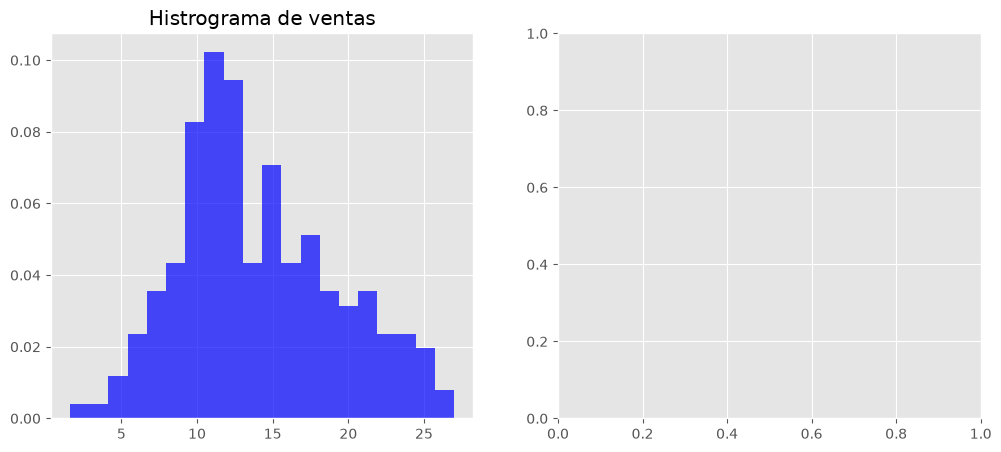

In [21]:
fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].hist(df['Sales'].dropna(), bins=20, color='blue', alpha=0.7, density=True)
ax[0].set_title('Histrograma de ventas')



In [22]:
df.corr() # Cerca de 0 es mala, cerca de -1/1 es que tiene correlacion lineal.

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


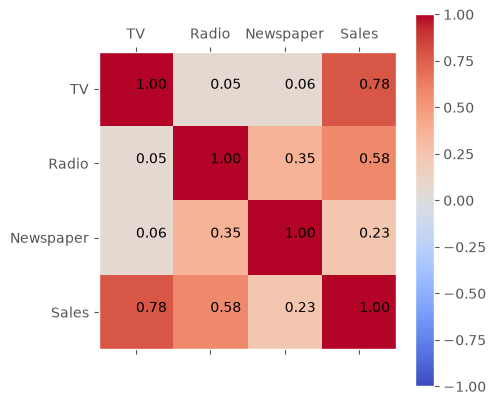

In [23]:
corr = df.corr() # Lo voy a usar para recorrer
plt.matshow(df.corr(), cmap='coolwarm', vmin=-1, vmax=1 ) #Aca recorro la variable y los muestro en el grafico
plt.grid(visible=False)
plt.xticks(range(len(df.columns)), df.columns)
plt.yticks(range(len(df.columns)), df.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f'{corr.iloc[i,j]:.2f}')
plt.colorbar()


In [28]:
y = df['Sales']
x = df[['TV']]




In [34]:
x_train, x_test, y_train, y_test= train_test_split(
    x, y, test_size=0.2, random_state=1
)

In [41]:
modelo = LinearRegression()

modelo.fit(x_train, y_train);

In [39]:
modelo.coef_ # X * coef_


array([0.0492751])

In [40]:
modelo.intercept_ # Ordenada al origin

np.float64(6.799773449796853)

In [42]:
y_pred = modelo.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)